# Classificação espectral de estrelas OBA — execução no Colab

Notebook único, de ponta a ponta: instala as dependências, obtém o pacote de
correção, monta o Drive, extrai os atributos dos espectros XP, treina o modelo
e roda os experimentos.

**Antes de começar**, coloque no seu Google Drive:

```
MeuDrive/oba_stars/
├── rf_oba_stars/       <- a pasta do pacote (com __init__.py, config.py, ...)
├── oba_stars.fits      <- os espectros
└── tests/              <- opcional, para rodar a suíte de testes
```

Tempo estimado da primeira execução completa: 15 a 20 minutos. As execuções
seguintes reaproveitam o cache da correção e levam cerca de 5 minutos.

> **Runtime.** CPU basta — Random Forest não usa GPU. Se o Colab desconectar,
> reexecute a partir da seção 1: o cache em disco evita refazer a etapa lenta.


## 1. Ambiente

In [1]:
#@title Instalar dependências { display-mode: "form" }
!pip install -q "numpy>=1.24" "pandas>=2.0" "scikit-learn>=1.3" \
    "matplotlib>=3.7" "scipy>=1.10" "joblib>=1.3" "astropy>=5.3" specutils

import numpy, pandas, sklearn, astropy
print("numpy      ", numpy.__version__)
print("pandas     ", pandas.__version__)
print("scikit-learn", sklearn.__version__)
print("astropy    ", astropy.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 984.6/984.6 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.9/110.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 364.6/364.6 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.1/174.1 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.3/49.3 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.8/105.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 350.3/350.3 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.3/59.3 kB 2.0 MB/s eta 0:00:00
numpy       2.1.3
pandas      2.2.3
scikit-learn 1.6.1
astropy     7.2.3


In [2]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [ ]:
#@title Montar o Google Drive { display-mode: "form" }
from google.colab import drive
drive.mount('/content/drive')          # <- sempre este, não mexer

# Aqui sim vai o caminho da sua pasta.
PROJETO = '/content/drive/MyDrive/Projeto'  #@param {type:"string"}

import os
assert os.path.isdir(PROJETO), f'Pasta não encontrada: {PROJETO}'
print('conteúdo da pasta do projeto:')
for item in sorted(os.listdir(PROJETO)):
    print('  ', item)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
conteúdo da pasta do projeto:
   .pytest_cache
   OBA_Stars_Colab.ipynb
   atributos_e_fontes.md
   b_star_fits_ra_dec.fits
   cache
   config.py
   experimentos_principal.csv
   experiments.csv
   features.py
   o_star_fits_ra_dec.fits
   ob_ra_dec.fits
   oba_stars.fits
   pyproject.toml
   relatorio_oba_stars.pdf
   resultados
   rf_oba_stars


In [ ]:
#@title Baixar o pacote de correção dos espectros { display-mode: "form" }
# Huang et al. (2024) — correção sistemática dos espectros XP do Gaia DR3.
# Baixado para o disco local do Colab, não para o Drive.
%cd /content
!rm -rf GaiaXPcorrection*
!wget -q https://codeload.github.com/HiromonGON/GaiaXPcorrection/zip/refs/heads/main -O gxp.zip
!unzip -q -o gxp.zip

CORRECAO = '/content/GaiaXPcorrection-main'
assert os.path.isdir(f'{CORRECAO}/GaiaDR3XPspectracorrectionV1')
print('pacote de correção pronto em', CORRECAO)

/content
pacote de correção pronto em /content/GaiaXPcorrection-main


In [ ]:
#@title Importar o pacote do projeto { display-mode: "form" }
import sys
sys.path.insert(0, PROJETO)

import rf_oba_stars as rf
print('rf_oba_stars versão', rf.__version__)

ESPECTROS = f'{PROJETO}/oba_stars.fits'
SAIDA     = '/content/saida'          # trabalho local, mais rápido que o Drive
CACHE     = f'{PROJETO}/cache'        # cache no Drive: sobrevive à desconexão

os.makedirs(SAIDA, exist_ok=True)
os.makedirs(f'{SAIDA}/figuras', exist_ok=True)
os.makedirs(CACHE, exist_ok=True)
assert os.path.isfile(ESPECTROS), f'Espectros não encontrados: {ESPECTROS}'
print('tudo pronto')

rf_oba_stars versão 0.5.0
tudo pronto


## 2. Verificação rápida (opcional)

Roda a suíte de testes. Leva poucos segundos e confirma que o pacote está
íntegro antes de investir tempo no processamento.

In [ ]:
!pip install -q pytest
!cd {PROJETO} && python -m pytest tests/ -q 2>&1 | tail -5

ERROR: file or directory not found: tests/


no tests ran in 0.01s


## 3. Extração dos atributos

Esta é a etapa lenta. O resultado da correção sistemática vai para o cache no
Drive, então só roda por inteiro na primeira vez.

In [ ]:

resultado = rf.run_feature_pipeline(
    ESPECTROS,
    correction_package_dir=CORRECAO,
    correction_cache=f'{CACHE}/correcao_oba.npz',
    use_corrected_flux=True,
    feature_mode='all',
    include_broadband=('color_mag', 'blue_red_norm', 'slope_norm',
                       'blue_red_ratio', 'blue_red_diff', 'slope'),
    remove_outliers=False,
    output_csv=f'{SAIDA}/oba_stars_features.csv',
    figures_dir=f'{SAIDA}/figuras',
    verbose=True,
)

features = resultado['features']
print()
print('histórico do fluxo de dados:', resultado['historico'])
features.head()

1. Leitura: 8862 estrelas, 343 pontos, 336–1020 nm
   distribuição: {'O': 562, 'B': 2032, 'A': 6268}
2. Correção sistemática: lida do cache /content/drive/MyDrive/Projeto/cache/correcao_oba.npz
   correções confiáveis: 8845/8862 (99.8%)
   espectros corrigidos adotados nas etapas seguintes
   após filtro de confiabilidade: 8845 estrelas
3. Corte de SNR ≥ 20: 8686 estrelas
4. Normalização pelo contínuo (método 'specutils')...


  normalizados 1000/8686 espectros
  normalizados 2000/8686 espectros
  normalizados 3000/8686 espectros
  normalizados 4000/8686 espectros
  normalizados 5000/8686 espectros
  normalizados 6000/8686 espectros
  normalizados 7000/8686 espectros
  normalizados 8000/8686 espectros
   AVISO: atributos com amplitude abaixo de 1e-07 são tratados como constantes pelo divisor de árvores do scikit-learn e recebem importância zero: ['blue_red_diff', 'slope']


/content/drive/MyDrive/Projeto/rf_oba_stars/feature_pipeline.py:245: UserWarning: Atributos com amplitude ≤ 1e-07 serão tratados como constantes pelas árvores do scikit-learn e ignorados pelo modelo: ['blue_red_diff', 'slope']. Use uma razão adimensional ou escalone essas colunas.
  escalas = preprocessing.check_feature_scales(tabela, warn=verbose)


5. Atributos extraídos (26): ['ew_h_alpha', 'ew_h_beta', 'ew_he_i_5876', 'ew_h_gamma', 'ew_ca_ii_k', 'ew_he_i_4471', 'ew_blend_4686', 'depth_h_delta', 'depth_h_gamma', 'depth_he_i_4471', 'depth_he_ii_4686', 'depth_h_beta', 'depth_he_i_5876', 'depth_h_alpha', 'he_ii', 'he_i', 'mg_ii', 'hbeta_deep', 'color_mag', 'blue_red_norm', 'slope_norm', 'blue_red_ratio', 'blue_red_diff', 'slope', 'C2', 'C3']
8. Figuras gravadas em /content/saida/figuras/
9. Tabela gravada em /content/saida/oba_stars_features.csv (8686 linhas)

histórico do fluxo de dados: {'carregadas': 8862, 'apos_caution': 8845, 'apos_snr': 8686, 'apos_extracao': 8686}


,source_id,ew_h_alpha,ew_h_beta,ew_he_i_5876,ew_h_gamma,ew_ca_ii_k,ew_he_i_4471,ew_blend_4686,depth_h_delta,depth_h_gamma,...,hbeta_deep,color_mag,blue_red_norm,slope_norm,blue_red_ratio,blue_red_diff,slope,C2,C3,spectral_type
0,251961924258399616,0.858152,4.165859,1.624027,5.571390,14.147948,-2.084058,-2.077344,-0.049675,-0.046161,...,-0.002331,-1.266417,0.524992,-0.959746,3.210458,6.842618e-14,-8.471139e-17,-0.439336,-0.156272,O
1,468876464407828096,-0.219731,0.142396,3.446723,-1.618077,-2.003720,3.711354,1.413950,-0.023699,-0.017656,...,0.001524,-0.956143,0.413910,-0.984558,2.412444,6.242615e-15,-1.077008e-17,-0.169996,-0.135180,O
2,506790923870949248,2.516041,0.733314,2.405460,0.075989,1.182524,2.776572,2.294054,-0.036439,-0.021142,...,-0.005849,-1.349751,0.552230,-1.296554,3.466574,1.028854e-14,-1.668427e-17,-0.342004,-0.206352,O
3,524109090999225344,3.249857,2.931953,2.194350,-0.450022,1.364267,3.557256,0.313425,-0.032318,-0.008968,...,-0.000551,-1.370421,0.558811,-1.552009,3.533202,7.682293e-15,-1.466088e-17,-0.328645,-0.212682,O
4,2014960718396556160,-0.475026,12.485859,1.680710,-1.553006,-20.529657,3.418629,1.316101,0.067177,0.067834,...,0.024548,1.161215,-0.489011,1.396575,0.343174,-7.620232e-16,1.664139e-18,0.422408,0.690223,O


### Conferência das bandas espectrais

Antes de confiar nos índices, vale confirmar que as bandas estão sobre as
feições. O teste desloca a banda central e acompanha o contraste entre as
médias de classe: um índice bem centrado tem máximo em deslocamento zero.

In [ ]:
import numpy as np

espectros = resultado['spectra']
classes = espectros.meta[rf.config.TARGET_COLUMN].to_numpy()

for nome in ['h_beta', 'he_i_4471', 'blend_4686']:
    scan = rf.band_shift_scan(espectros.flux, classes, nome,
                              shifts_nm=np.arange(-8, 9, 2.0))
    melhor = scan.loc[scan['contraste'].idxmax()]
    print(f"{nome:12} contraste máximo em {melhor['deslocamento_nm']:+.0f} nm "
          f"(centro {melhor['centro_nm']:.0f} nm)")

h_beta       contraste máximo em +0 nm (centro 486 nm)
he_i_4471    contraste máximo em +0 nm (centro 447 nm)
blend_4686   contraste máximo em -2 nm (centro 467 nm)


In [ ]:
# Comportamento físico dos índices: Balmer cresce de O para A, He I decresce.
ews = [c for c in features.columns if c.startswith('ew_')]
features.groupby(rf.config.TARGET_COLUMN)[ews].mean().round(2)

,ew_h_alpha,ew_h_beta,ew_he_i_5876,ew_h_gamma,ew_ca_ii_k,ew_he_i_4471,ew_blend_4686
spectral_type,,,,,,,
A,11.84,14.52,0.43,14.69,-5.61,-6.78,-1.66
B,1.33,5.86,1.14,6.55,-3.89,-0.03,0.87
O,0.43,5.36,2.71,0.25,-7.14,2.60,1.78


## 4. Classificação principal

Conjunto de atributos restrito aos diagnósticos com correspondência direta aos
critérios MK: região de He II 4686, He I 4471, Hβ, cor, inclinação do contínuo
e os coeficientes C2 e C3.

In [ ]:
PRINCIPAL = list(rf.config.FEATURES_PRINCIPAL)
print(PRINCIPAL)

X, y = features[PRINCIPAL], features[rf.config.TARGET_COLUMN]
splits = rf.train_val_test_split(X, y)

for nome, n in splits.sizes.items():
    print(f'{nome.capitalize():<11}: {n:>6}  ({splits.proportions[nome]:.2f}%)')

['ew_blend_4686', 'ew_he_i_4471', 'ew_h_beta', 'color_mag', 'slope_norm', 'C2', 'C3']
Treino     :   6079  (69.99%)
Validacao  :   1304  (15.01%)
Teste      :   1303  (15.00%)


In [ ]:
modelo = rf.build_random_forest()

scores = rf.cross_validate_model(modelo, splits.X_train, splits.y_train,
                                 cv=rf.build_cv())
resumo = rf.summarize_scores(scores)
print('acurácia por dobra:', scores.round(4))
print(f"média: {resumo['media']:.4f} ± {resumo['desvio_padrao']:.4f}")

acurácia por dobra: [0.8757 0.8723 0.8585 0.8744 0.8525 0.8652 0.8802]
média: 0.8684 ± 0.0093


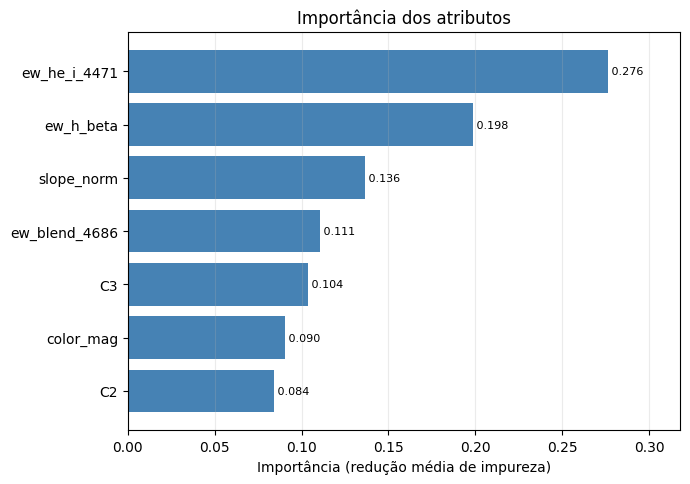

,0
ew_he_i_4471,0.2763
ew_h_beta,0.1984
slope_norm,0.1364
ew_blend_4686,0.1108
C3,0.1038
color_mag,0.0903
C2,0.0840


In [ ]:
modelo = rf.fit_model(modelo, splits.X_train, splits.y_train)

importancias = rf.feature_importances(modelo)
rf.plot_feature_importances(importancias)
importancias.round(4)

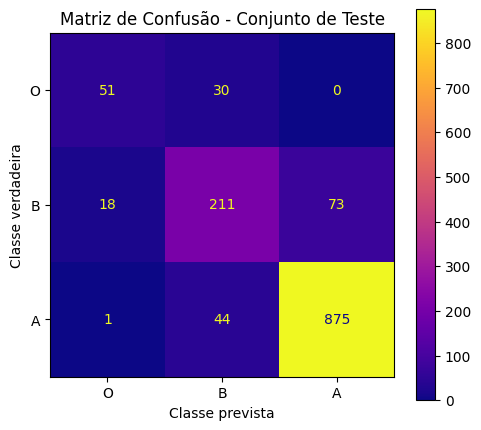

Acurácia (Teste): 0.8726

classe        precisão   revocação      f1   suporte
O               0.7286      0.6296  0.6755        81
B               0.7404      0.6987  0.7189       302
A               0.9230      0.9511  0.9368       920

acurácia        0.8726

macro F1: 0.7771


In [ ]:
resultado_teste = rf.evaluate_model(
    modelo, splits.X_test, splits.y_test,
    set_name='Teste', labels=list(rf.config.CLASS_ORDER),
    save_path=f'{SAIDA}/figuras/matriz_confusao_principal.png',
)
rf.print_evaluation(resultado_teste)
print(f"\nmacro F1: {resultado_teste['relatorio']['macro avg']['f1-score']:.4f}")

In [ ]:
# Onde estão os erros
rf.confusion_pairs(splits.y_test, resultado_teste['y_pred'])

,verdadeira,prevista,n,pct_da_classe
0,B,A,73,24.17
1,A,B,44,4.78
2,O,B,30,37.04
3,B,O,18,5.96
4,A,O,1,0.11


## 5. Experimentos pós-classificação

Os atributos adicionais — Hα, Hγ, Ca II K, He I 5876 e a cor normalizada —
entram aqui, como testes sobre a classificação de referência.

E01 principal (MK)                             acc 0.8689  F1m 0.7637 ± 0.0101
E02 principal + H-alfa                         acc 0.8774  F1m 0.7946 ± 0.0170
E03 principal + H-gama                         acc 0.8836  F1m 0.8154 ± 0.0110
E04 principal + Ca II K                        acc 0.8782  F1m 0.7970 ± 0.0112
E05 principal + He I 5876                      acc 0.8707  F1m 0.7618 ± 0.0145
E06 estendido (todos)                          acc 0.8876  F1m 0.8242 ± 0.0111
E07 só os atributos de teste                   acc 0.8730  F1m 0.7983 ± 0.0108


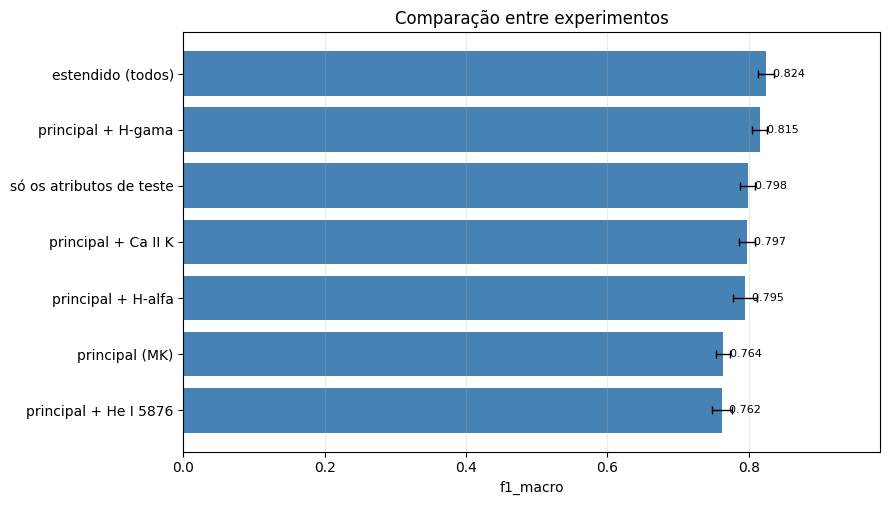

<Axes: title={'center': 'Comparação entre experimentos'}, xlabel='f1_macro'>

In [ ]:
conjuntos = {
    'principal (MK)':                 list(rf.config.FEATURES_PRINCIPAL),
    'principal + H-alfa':             list(rf.config.FEATURES_PRINCIPAL) + ['ew_h_alpha'],
    'principal + H-gama':             list(rf.config.FEATURES_PRINCIPAL) + ['ew_h_gamma'],
    'principal + Ca II K':            list(rf.config.FEATURES_PRINCIPAL) + ['ew_ca_ii_k'],
    'principal + He I 5876':          list(rf.config.FEATURES_PRINCIPAL) + ['ew_he_i_5876'],
    'estendido (todos)':              list(rf.config.FEATURES_ESTENDIDO),
    'só os atributos de teste':       list(rf.config.FEATURES_EXTRA),
}

comparacao = rf.run_experiments(features, conjuntos, table_name='colab')
rf.append_experiments(comparacao, f'{CACHE}/experiments.csv')
rf.plot_experiment_comparison(comparacao)

### Varredura de hiperparâmetros

Cada parâmetro é variado isoladamente sobre a configuração base.

Nota: Leva alguns minutos.

In [ ]:
grade = {
    'n_estimators':     [25, 50, 101, 200],
    'max_depth':        [5, 10, 15, 25, None],
    'min_samples_leaf': [1, 2, 5, 10],
    'class_weight':     ['balanced', None],
}
varredura = rf.run_hyperparameter_sweep(features, PRINCIPAL, grade)
varredura.to_csv(f'{SAIDA}/varredura_hiperparametros.csv', index=False)
varredura

n_estimators       =     25   acc 0.8663   F1m 0.7623 ± 0.0132
n_estimators       =     50   acc 0.8679   F1m 0.7612 ± 0.0136
n_estimators       =    101   acc 0.8689   F1m 0.7637 ± 0.0101
n_estimators       =    200   acc 0.8685   F1m 0.7645 ± 0.0109
max_depth          =      5   acc 0.8347   F1m 0.7391 ± 0.0175
max_depth          =     10   acc 0.8595   F1m 0.7717 ± 0.0105
max_depth          =     15   acc 0.8690   F1m 0.7692 ± 0.0130
max_depth          =     25   acc 0.8689   F1m 0.7637 ± 0.0101
max_depth          =   None   acc 0.8683   F1m 0.7630 ± 0.0098
min_samples_leaf   =      1   acc 0.8689   F1m 0.7637 ± 0.0101
min_samples_leaf   =      2   acc 0.8645   F1m 0.7668 ± 0.0188
min_samples_leaf   =      5   acc 0.8579   F1m 0.7666 ± 0.0111
min_samples_leaf   =     10   acc 0.8470   F1m 0.7537 ± 0.0137
class_weight       = balanced   acc 0.8689   F1m 0.7637 ± 0.0101
class_weight       =   None   acc 0.8685   F1m 0.7644 ± 0.0120


,hiperparametro,valor,acuracia,acuracia_dp,f1_macro,f1_macro_dp
0,n_estimators,25,0.8663,0.0108,0.7623,0.0132
1,n_estimators,50,0.8679,0.0087,0.7612,0.0136
2,n_estimators,101,0.8689,0.0067,0.7637,0.0101
3,n_estimators,200,0.8685,0.0083,0.7645,0.0109
4,max_depth,5,0.8347,0.0122,0.7391,0.0175
5,max_depth,10,0.8595,0.0089,0.7717,0.0105
6,max_depth,15,0.8690,0.0098,0.7692,0.0130
7,max_depth,25,0.8689,0.0067,0.7637,0.0101
8,max_depth,None,0.8683,0.0078,0.7630,0.0098
9,min_samples_leaf,1,0.8689,0.0067,0.7637,0.0101


### Curva de aprendizado

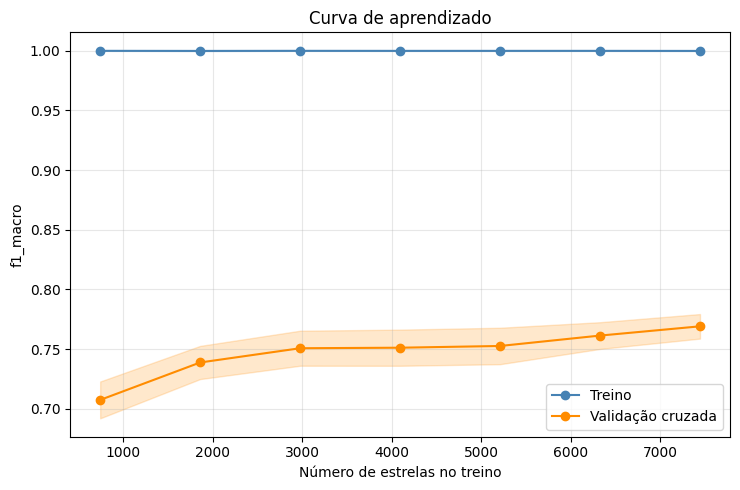

,n_amostras,treino_media,treino_dp,validacao_media,validacao_dp
0,744,1.0000,0.0000,0.7074,0.0154
1,1861,0.9999,0.0002,0.7388,0.0139
2,2978,1.0000,0.0000,0.7507,0.0147
3,4094,1.0000,0.0001,0.7512,0.0152
4,5211,1.0000,0.0001,0.7526,0.0153
5,6328,1.0000,0.0001,0.7613,0.0112
6,7445,0.9999,0.0001,0.7691,0.0103


In [ ]:
curva = rf.learning_curve_data(X, y)
rf.plot_learning_curve(curva)
curva.round(4)

## 6. Análise exploratória

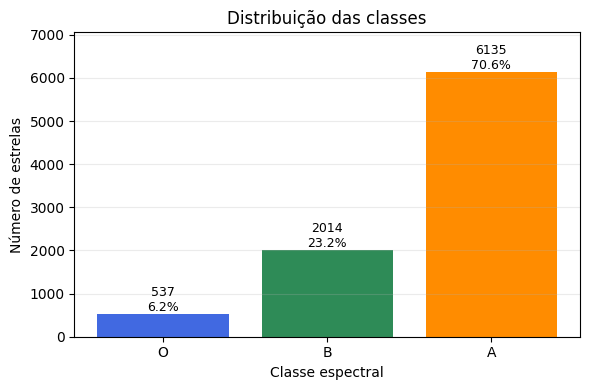

,n,percentual,razao_para_maior
spectral_type,,,
O,537,6.182362,0.087531
B,2014,23.186737,0.328280
A,6135,70.630900,1.000000


In [ ]:
rf.plot_class_balance(features)
rf.class_balance(features)

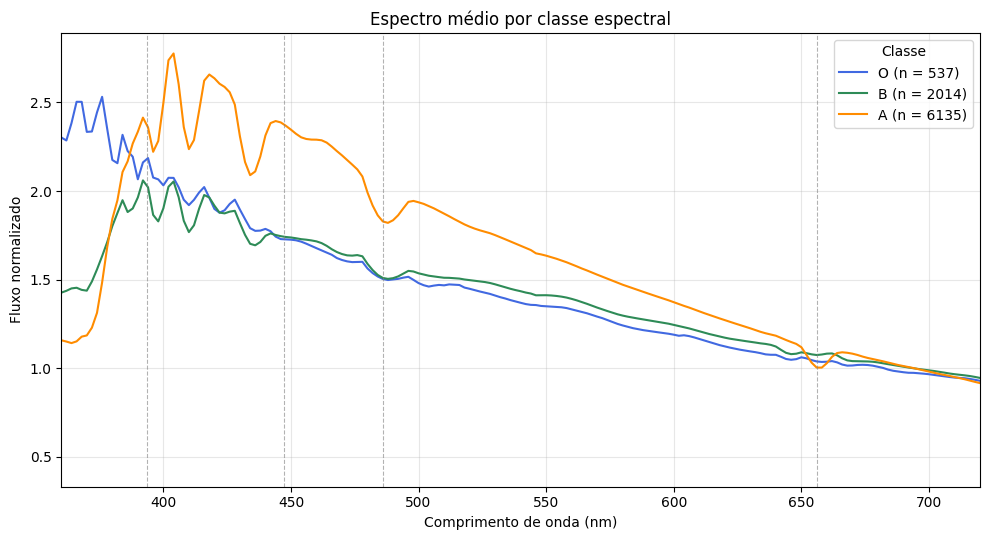

<Axes: title={'center': 'Espectro médio por classe espectral'}, xlabel='Comprimento de onda (nm)', ylabel='Fluxo normalizado'>

In [ ]:
rf.plot_mean_spectra_by_class(
    espectros,
    lines=['h_beta', 'he_i_4471', 'h_alpha', 'ca_ii_k'],
    xlim=(360, 720),
)

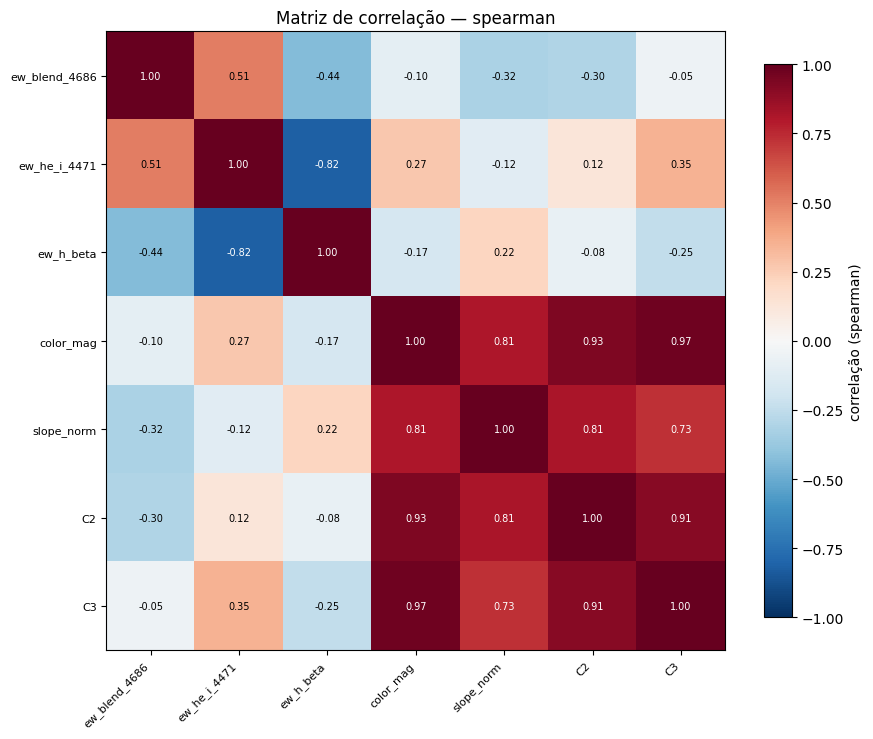

<Axes: title={'center': 'Matriz de correlação — spearman'}>

In [ ]:
rf.plot_correlation_heatmap(features, PRINCIPAL, method='spearman')

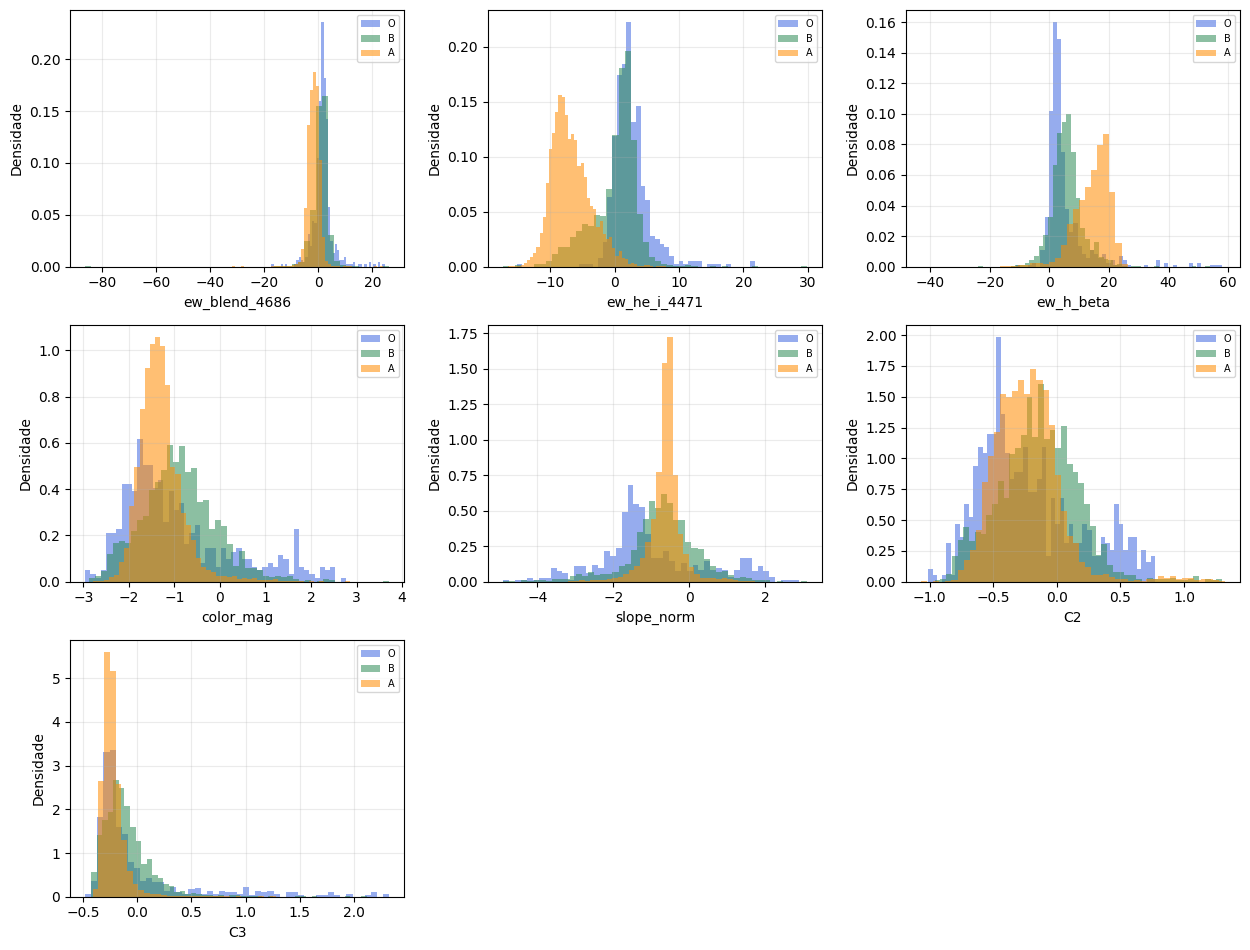

array([<Axes: xlabel='ew_blend_4686', ylabel='Densidade'>,
       <Axes: xlabel='ew_he_i_4471', ylabel='Densidade'>,
       <Axes: xlabel='ew_h_beta', ylabel='Densidade'>,
       <Axes: xlabel='color_mag', ylabel='Densidade'>,
       <Axes: xlabel='slope_norm', ylabel='Densidade'>,
       <Axes: xlabel='C2', ylabel='Densidade'>,
       <Axes: xlabel='C3', ylabel='Densidade'>, <Axes: >, <Axes: >],
      dtype=object)

In [ ]:
rf.plot_feature_distributions(features, PRINCIPAL)

## 7. Salvar os resultados no Drive

In [ ]:
import shutil

DESTINO = f'{PROJETO}/resultados'
os.makedirs(DESTINO, exist_ok=True)

rf.save_model(modelo, f'{DESTINO}/modelo_rf_principal.joblib')

for arquivo in os.listdir(SAIDA):
    origem = f'{SAIDA}/{arquivo}'
    if os.path.isfile(origem):
        shutil.copy(origem, DESTINO)

os.makedirs(f'{DESTINO}/figuras', exist_ok=True)
for figura in os.listdir(f'{SAIDA}/figuras'):
    shutil.copy(f'{SAIDA}/figuras/{figura}', f'{DESTINO}/figuras')

print('gravado em', DESTINO)
for item in sorted(os.listdir(DESTINO)):
    print('  ', item)

gravado em /content/drive/MyDrive/Projeto/resultados
   figuras
   modelo_rf_principal.joblib
   oba_stars_features.csv
   varredura_hiperparametros.csv


## 8. Variantes úteis

**Sem o pacote de correção.** Se não quiser aplicar a correção sistemática,
omita `correction_package_dir`. As colunas C2 e C3 não serão geradas e o
conjunto principal precisa ser reduzido:

```python
resultado = rf.run_feature_pipeline(ESPECTROS, feature_mode='ew',
                                    output_csv=f'{SAIDA}/features.csv')
PRINCIPAL = [c for c in rf.config.FEATURES_PRINCIPAL if c not in ('C2', 'C3')]
```

**Mais rápido.** Sem normalização por contínuo (os índices de três bandas não
precisam dela) e sem as figuras:

```python
resultado = rf.run_feature_pipeline(
    ESPECTROS, correction_package_dir=CORRECAO,
    correction_cache=f'{CACHE}/correcao_oba.npz',
    feature_mode='ew', continuum_method='median_filter',
    figures_dir=None, verbose=False,
)
```

**Reproduzir o caderno antigo.** Para comparar com os resultados anteriores:

```python
resultado = rf.run_feature_pipeline(ESPECTROS, correction_package_dir=CORRECAO,
                                    feature_mode='legacy',
                                    use_corrected_flux=False)
X, y = rf.split_features_target(resultado['features'], drop_id=False)
```

**Auditar janelas de índices.** Traduz posições de array para comprimento de
onda e aponta a linha mais próxima:

```python
rf.audit_legacy_windows()
```

**Por linha de comando**, se preferir:

```bash
!cd {PROJETO} && python -m rf_oba_stars.feature_pipeline \
    --spectra oba_stars.fits --correction-dir {CORRECAO} \
    --mode ew --output features.csv --figures-dir figuras
```


## 9. Problemas comuns

| Sintoma | Causa | Solução |
|---|---|---|
| `ModuleNotFoundError: rf_oba_stars` | pasta do pacote fora do caminho | confira que `PROJETO` aponta para a pasta que **contém** `rf_oba_stars/` |
| `TypeError: only 0-dimensional arrays...` | pacote de correção com NumPy 2 | já tratado; se aparecer, confirme que está usando `rf.correct_spectra` e não o pacote direto |
| `O cache tem N linhas, mas...` | cache de uma amostra diferente | apague `cache/correcao_oba.npz` |
| Sessão cai durante a correção | tempo limite do Colab | reexecute; o cache retoma de onde parou |
| `AVISO: atributos com amplitude abaixo de 1e-07` | atributo em escala absoluta | esperado se incluir `slope` ou `blue_red_diff`; use `slope_norm` e `blue_red_norm` |
| Figuras não aparecem | backend do matplotlib | `%matplotlib inline` na primeira célula |


## 10. Inferência de Parâmetros

In [ ]:
pip install astroquery

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 43.9 MB/s eta 0:00:00


In [ ]:
from astroquery.vizier import Vizier
import pandas as pd

Vizier.ROW_LIMIT = -1

# ---------- PASSO 1: Descobrir quantas tabelas o paper publicou ----------
tabelas = Vizier.get_catalogs("J/ApJS/257/54")
print(f"Número de tabelas no catálogo: {len(tabelas)}")
for i, t in enumerate(tabelas):
    desc = t.meta.get("description", "sem descrição")
    print(f"  [{i}] {len(t):>6} linhas — {desc}")

Número de tabelas no catálogo: 2
  [0]  22292 linhas — The predicted stellar labels of 16032 LAMOST-LRS (Liu+ 2019, J/ApJS/241/32) early-type stars
  [1]   9287 linhas — The predicted stellar parameters of 9238 LAMOST-MRS (Guo+ 2022RAA....22b5009G) early-type stars


In [ ]:
# ---------- PASSO 2: Inspecionar colunas da tabela escolhida ----------
# Ajuste o índice conforme o print acima
cat = tabelas[0]

print("Colunas disponíveis:")
print(cat.colnames)
print("\nPrimeiras 3 linhas:")
print(cat[:3])

Colunas disponíveis:
['ObsID', 'RAJ2000', 'DEJ2000', 'SNR', 'Teff', 'log(g)', '[M/H]', 'vsin(i)', 'Flag', 'DR4+DR5']

Primeiras 3 linhas:
  ObsID   RAJ2000  DEJ2000  SNR  Teff ...  [M/H]   vsin(i) Flag DR4+DR5
            deg      deg          K   ... log(Sun)  km / s             
--------- -------- -------- --- ----- ... -------- ------- ---- -------
365008241 283.4841  42.5822 283  5079 ...    -2.43       0    O DR4+DR5
362415197  74.7555  40.5032 114  7758 ...    -1.95       0    O DR4+DR5
125210155  78.1786  40.2200  82 18202 ...     0.09       0    O DR4+DR5


In [ ]:
# ---------- PASSO 3: Entender as flags e a distribuição real ----------
import pandas as pd

df = cat.to_pandas()
print("Total de linhas:", len(df))

print("\nValores únicos de Flag e contagem:")
print(df["Flag"].value_counts(dropna=False))

print("\nEstatística de Teff (todas as linhas):")
print(df["Teff"].describe())

print("\nEstatística de Teff apenas em Flag='O':")
print(df.loc[df["Flag"] == "O", "Teff"].describe())

Total de linhas: 22292

Valores únicos de Flag e contagem:
Flag
O    18361
I     3931
Name: count, dtype: int64

Estatística de Teff (todas as linhas):
count    22292.00000
mean     15272.22138
std       6201.93614
min     -36654.00000
25%      11634.75000
50%      13601.00000
75%      17159.00000
max      69857.00000
Name: Teff, dtype: float64

Estatística de Teff apenas em Flag='O':
count    18361.000000
mean     14025.915310
std       5485.379629
min     -36654.000000
25%      11212.000000
50%      12859.000000
75%      14818.000000
max      69857.000000
Name: Teff, dtype: float64


In [ ]:
# ---------- PASSO 4: Verificar duplicatas por posição ----------
# Guo alerta que a mesma estrela pode ter várias ObsID.
# Agrupamos por posição arredondada como proxy rápido:
df["ra_round"] = df["RAJ2000"].round(4)
df["dec_round"] = df["DEJ2000"].round(4)
n_unicas = df.groupby(["ra_round", "dec_round"]).ngroups
print(f"Espectros: {len(df)}, estrelas únicas (aprox): {n_unicas}")
print(f"Duplicação média: {len(df) / n_unicas:.2f} espectros/estrela")

Espectros: 22292, estrelas únicas (aprox): 16203
Duplicação média: 1.38 espectros/estrela


In [ ]:
import numpy as np

# ---------- PASSO 5: Filtrar Flag='I' e deduplicar por posição ----------

# 5a. Filtro
gold = df[df["Flag"] == "I"].copy()
print(f"Após filtro Flag='I': {len(gold)} espectros")

# 5b. Sanity check: nenhuma linha com Teff/logg inválidos
print(f"NaN em Teff: {gold['Teff'].isna().sum()}")
print(f"NaN em log(g): {gold['log(g)'].isna().sum()}")

# 5c. Deduplicação por posição, mantendo maior SNR
# Arredonda coordenadas para ~0.5 arcsec (0.0001° ~ 0.36 arcsec, seguro)
gold["ra_key"]  = gold["RAJ2000"].round(4)
gold["dec_key"] = gold["DEJ2000"].round(4)

# Ordena por SNR decrescente e mantém o primeiro de cada grupo
gold_sorted = gold.sort_values("SNR", ascending=False)
gold_unique = gold_sorted.drop_duplicates(subset=["ra_key", "dec_key"], keep="first")

# Limpa colunas auxiliares
gold_unique = gold_unique.drop(columns=["ra_key", "dec_key"]).reset_index(drop=True)

print(f"\nApós deduplicação: {len(gold_unique)} estrelas únicas")
print(f"Redução: {len(gold) - len(gold_unique)} espectros duplicados removidos")

# 5d. Distribuição final
print("\nDistribuição de Teff (estrelas únicas):")
print(gold_unique["Teff"].describe())

# 5e. Guardar para próximo passo
print(f"\nDataFrame pronto: gold_unique com {len(gold_unique)} linhas e colunas {list(gold_unique.columns)}")

Após filtro Flag='I': 3931 espectros
NaN em Teff: 0
NaN em log(g): 0

Após deduplicação: 2752 estrelas únicas
Redução: 1179 espectros duplicados removidos

Distribuição de Teff (estrelas únicas):
count     2752.000000
mean     21297.693314
std       6382.003688
min      15092.000000
25%      17221.000000
50%      19286.500000
75%      22665.000000
max      53708.000000
Name: Teff, dtype: float64

DataFrame pronto: gold_unique com 2752 linhas e colunas ['ObsID', 'RAJ2000', 'DEJ2000', 'SNR', 'Teff', 'log(g)', '[M/H]', 'vsin(i)', 'Flag', 'DR4+DR5', 'ra_round', 'dec_round']


In [ ]:
from astropy.coordinates import SkyCoord
import astropy.units as u
import numpy as np
import pandas as pd

# ---------- PASSO 6: Crossmatch posicional Guo × sua amostra OB ----------

# 6a. Carregar sua tabela (se ainda não estiver em memória)
from astropy.table import Table
ob_coords = Table.read("ob_ra_dec.fits").to_pandas()
# Decodifica classe se vier como bytes
if isinstance(ob_coords["classe"].iloc[0], bytes):
    ob_coords["classe"] = ob_coords["classe"].str.decode("utf-8").str.strip()

# 6b. Construir SkyCoord dos dois lados
coords_guo = SkyCoord(
    ra=gold_unique["RAJ2000"].values * u.deg,
    dec=gold_unique["DEJ2000"].values * u.deg,
    frame="icrs"
)

coords_meu = SkyCoord(
    ra=ob_coords["ra"].values * u.deg,
    dec=ob_coords["dec"].values * u.deg,
    frame="icrs"
)

# 6c. Para cada estrela do Guo, achar a mais próxima na minha amostra
idx, sep, _ = coords_guo.match_to_catalog_sky(coords_meu)
sep_arcsec = sep.to(u.arcsec).value

# 6d. Diagnóstico da distribuição
print("Separações angulares Guo → minha amostra (arcsec):")
print(f"  min:      {sep_arcsec.min():.3f}")
print(f"  mediana:  {np.median(sep_arcsec):.3f}")
print(f"  90%:      {np.percentile(sep_arcsec, 90):.3f}")
print(f"  max:      {sep_arcsec.max():.3f}")

print("\nCasamentos aceitos em vários raios de tolerância:")
for r in [0.5, 1.0, 2.0, 5.0]:
    n = (sep_arcsec < r).sum()
    print(f"  < {r:>4.1f} arcsec: {n:>4} pares")

# 6e. Aplicar tolerância de 1 arcsec (padrão para Gaia-derived)
mask = sep_arcsec < 1.0
n_matches = mask.sum()
print(f"\n>>> Matches aceitos (< 1 arcsec): {n_matches}")

# 6f. Montar DataFrame de labels: uma linha por match aceito
labels_df = pd.DataFrame({
    "source_id":  ob_coords["source_id"].values[idx[mask]],
    "classe":     ob_coords["classe"].values[idx[mask]],
    "Teff":       gold_unique["Teff"].values[mask],
    "logg":       gold_unique["log(g)"].values[mask],
    "M_H":        gold_unique["[M/H]"].values[mask],
    "vsini":      gold_unique["vsin(i)"].values[mask],
    "SNR_lamost": gold_unique["SNR"].values[mask],
    "sep_arcsec": sep_arcsec[mask],
})

print(f"\nLabels prontos: {len(labels_df)} linhas × {len(labels_df.columns)} colunas")
print(f"\nDistribuição de classe entre os matched:")
print(labels_df["classe"].value_counts())
print(f"\nEstatística de Teff dos matched:")
print(labels_df["Teff"].describe())
print(f"\nPrimeiras 5 linhas:")
print(labels_df.head())

# 6g. Salvar em disco (ponto de restauração)
labels_df.to_csv("labels_teff_logg.csv", index=False)
print(f"\nSalvo: labels_teff_logg.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'ob_ra_dec.fits'

In [ ]:
# Quantas das suas OB estão em céu acessível ao LAMOST (Dec > -10°)?
n_norte = (ob_coords["dec"] > -10).sum()
print(f"Suas OB com Dec > -10° (visíveis pelo LAMOST): {n_norte} / {len(ob_coords)}")

# Distribuição de magnitude vs. limite do LAMOST
print(f"\nSuas OB com G < 9 (brilhantes demais pro LAMOST): "
      f"{(ob_coords['phot_g_mean_mag'] < 9).sum()}")
print(f"Suas OB com 9 < G < 17 (janela do LAMOST): "
      f"{((ob_coords['phot_g_mean_mag'] >= 9) & (ob_coords['phot_g_mean_mag'] < 17)).sum()}")

In [ ]:
import pandas as pd

FEATURES_PATH = "/content/drive/MyDrive/Projeto/resultados/oba_stars_features.csv"
features_df = pd.read_csv(FEATURES_PATH)

# Reconfirma
print(f"features_df: {len(features_df)} linhas")
print(f"labels_df:   {len(labels_df)} linhas")  # deve existir ainda

In [ ]:
# Diagnóstico das duplicatas
duplicados = labels_df[labels_df["source_id"].duplicated(keep=False)].sort_values("source_id")
print(f"Total de linhas com source_id duplicado: {len(duplicados)}")
print(f"Número de source_ids únicos duplicados: {duplicados['source_id'].nunique()}")
print(f"\nExemplos:")
print(duplicados[["source_id", "Teff", "logg", "SNR_lamost", "sep_arcsec"]].head(10))

In [ ]:
# Redefine FEATURES antes de rodar o merge
from rf_oba_stars import config
FEATURES = list(config.FEATURES_PRINCIPAL)
print(f"FEATURES: {FEATURES}")

In [ ]:
# Deduplica labels_df: para cada source_id, mantém maior SNR do LAMOST
labels_df_unique = (
    labels_df
    .sort_values("SNR_lamost", ascending=False)
    .drop_duplicates(subset="source_id", keep="first")
    .reset_index(drop=True)
)

print(f"labels_df antes: {len(labels_df)}")
print(f"labels_df após dedup: {len(labels_df_unique)}")

# Sobrescreve o CSV (versão final e limpa)
labels_df_unique.to_csv("labels_teff_logg.csv", index=False)

# Merge com features
train_df = labels_df_unique.merge(
    features_df[["source_id"] + FEATURES],
    on="source_id",
    how="inner",
    validate="1:1"
)

print(f"\nAmostra final: {len(train_df)} estrelas")
print(f"Distribuição de classe: {train_df['classe'].value_counts().to_dict()}")
print(f"\nNaN em features: {train_df[FEATURES].isna().sum().sum()}")
print(f"NaN em Teff: {train_df['Teff'].isna().sum()}")

print(f"\nEstatística das features:")
print(train_df[FEATURES].describe().T[["mean", "std", "min", "max"]].round(4))

print(f"\nEstatística de Teff:")
print(train_df["Teff"].describe().round(0))

# Salva o dataset de treino consolidado (features + labels)
train_df.to_csv("train_teff.csv", index=False)
print(f"\nSalvo: train_teff.csv")

In [ ]:
# ---------- PASSO 8: Smoke test — primeiro RF Regressor ----------
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Preparar X e y
X = train_df[FEATURES].values
y = train_df["Teff"].values

print(f"X shape: {X.shape}, y shape: {y.shape}")

# Split 80/20 estratificado por bin de Teff (garante distribuição parecida em treino e teste)
# Cria 3 bins de Teff em quantis para estratificar
bins_teff = np.digitize(y, np.quantile(y, [0.33, 0.67]))

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=bins_teff,
    random_state=71,
)

print(f"Treino: {len(X_train)}, Teste: {len(X_test)}")

# Modelo — hiperparâmetros conservadores para amostra pequena
rf_reg = RandomForestRegressor(
    n_estimators=301,
    max_depth=11,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=71,
    n_jobs=-1,
)

rf_reg.fit(X_train, y_train)

# Predições
y_pred_train = rf_reg.predict(X_train)
y_pred_test  = rf_reg.predict(X_test)

# Métricas
def metricas(y_true, y_pred, nome):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    bias = np.mean(y_pred - y_true)
    print(f"\n{nome}:")
    print(f"  MAE:   {mae:>8.0f} K")
    print(f"  RMSE:  {rmse:>8.0f} K")
    print(f"  R²:    {r2:>8.3f}")
    print(f"  bias:  {bias:>+8.0f} K")

metricas(y_train, y_pred_train, "Treino")
metricas(y_test,  y_pred_test,  "Teste")

# Importância das features
print("\nImportância das features:")
importancias = sorted(zip(FEATURES, rf_reg.feature_importances_),
                       key=lambda x: -x[1])
for feat, imp in importancias:
    print(f"  {feat:<20} {imp:.4f}")

In [ ]:
# ---------- PASSO 9: K-Fold estratificado (métricas oficiais) ----------
from sklearn.model_selection import StratifiedKFold

bins_teff = np.digitize(y, np.quantile(y, [0.25, 0.50, 0.75]))
print(f"Distribuição de bins: {np.bincount(bins_teff)}")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=71)

resultados_folds = []
for i, (idx_train, idx_test) in enumerate(skf.split(X, bins_teff), 1):
    X_tr, X_te = X[idx_train], X[idx_test]
    y_tr, y_te = y[idx_train], y[idx_test]

    rf = RandomForestRegressor(
        n_estimators=301,      # ← atualizado
        max_depth=11,          # ← atualizado
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=71,       # ← atualizado
        n_jobs=-1,
    )
    rf.fit(X_tr, y_tr)
    y_pred = rf.predict(X_te)

    resultados_folds.append({
        "fold": i,
        "n_test": len(y_te),
        "MAE":  mean_absolute_error(y_te, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_te, y_pred)),
        "R2":   r2_score(y_te, y_pred),
        "bias": np.mean(y_pred - y_te),
    })

folds_df = pd.DataFrame(resultados_folds)
print("\nResultados por fold:")
print(folds_df.round(1).to_string(index=False))

print(f"\n===== MÉTRICAS AGREGADAS (média ± desvio entre folds) =====")
for metrica in ["MAE", "RMSE", "R2", "bias"]:
    m = folds_df[metrica].mean()
    s = folds_df[metrica].std()
    unidade = " K" if metrica in ("MAE", "RMSE", "bias") else ""
    print(f"  {metrica:>5}: {m:>8.1f} ± {s:.1f}{unidade}")

folds_df.to_csv("regression_kfold_results.csv", index=False)

In [ ]:
# ---------- PASSO 9b: Onde estão os erros? Predições OOF ----------
from sklearn.model_selection import StratifiedKFold

bins_teff = np.digitize(y, np.quantile(y, [0.25, 0.50, 0.75]))

# Loop manual estratificado (cross_val_predict não aceita stratify em y contínuo)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=71)  # ← mesma seed do PASSO 9
y_pred_oof = np.zeros_like(y, dtype=float)

for idx_train, idx_test in skf.split(X, bins_teff):
    rf = RandomForestRegressor(
        n_estimators=301,      # ← atualizado
        max_depth=11,          # ← atualizado
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=71,       # ← atualizado
        n_jobs=-1,
    )
    rf.fit(X[idx_train], y[idx_train])
    y_pred_oof[idx_test] = rf.predict(X[idx_test])

train_df["Teff_pred"] = y_pred_oof
train_df["residuo"]   = y_pred_oof - y

print("Resíduos por bin de Teff:")
bins_labels = ["15-19 kK", "19-22 kK", "22-26 kK", ">26 kK"]
train_df["bin_teff"] = pd.cut(
    train_df["Teff"],
    bins=[15000, 19000, 22000, 26000, 50000],
    labels=bins_labels,
)
print(train_df.groupby("bin_teff", observed=True)["residuo"].agg(
    ["count", "mean", "std", lambda x: np.abs(x).mean()]
).rename(columns={"<lambda_0>": "MAE"}).round(0))

print(f"\nResíduos por classe:")
print(train_df.groupby("classe")["residuo"].agg(
    ["count", "mean", "std", lambda x: np.abs(x).mean()]
).rename(columns={"<lambda_0>": "MAE"}).round(0))

print(f"\n5 estrelas com maior erro absoluto:")
piores = train_df.reindex(
    train_df["residuo"].abs().sort_values(ascending=False).index
).head(5)
print(piores[["source_id", "classe", "Teff", "Teff_pred", "residuo"]].round(0).to_string(index=False))

In [ ]:
# ---------- PASSO 10: Figuras principais do paper ----------
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import StratifiedKFold
import os

# Cria diretório de saída se não existir
FIG_DIR = "/content/drive/MyDrive/Projeto/resultados/figuras"
os.makedirs(FIG_DIR, exist_ok=True)

# ---------- Recomputar predições OOF + incerteza por estrela ----------
# Bins de estratificação — mesmos dos PASSOS 9 e 9b
bins_teff = np.digitize(y, np.quantile(y, [0.25, 0.50, 0.75]))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=71)
y_pred_oof = np.zeros_like(y, dtype=float)
y_std_oof  = np.zeros_like(y, dtype=float)  # incerteza (std entre árvores)

# Também coleta MAE por fold para agregação idêntica ao PASSO 9
mae_por_fold = []

for idx_train, idx_test in skf.split(X, bins_teff):
    rf = RandomForestRegressor(
        n_estimators=301, max_depth=11, min_samples_leaf=5,
        max_features="sqrt", random_state=71, n_jobs=-1,
    )
    rf.fit(X[idx_train], y[idx_train])
    # Predição por árvore para calcular std entre árvores
    preds_por_arvore = np.array([tree.predict(X[idx_test]) for tree in rf.estimators_])
    y_pred_oof[idx_test] = preds_por_arvore.mean(axis=0)
    y_std_oof[idx_test]  = preds_por_arvore.std(axis=0)
    # MAE deste fold, para agregar depois como média-entre-folds
    mae_fold = np.mean(np.abs(y_pred_oof[idx_test] - y[idx_test]))
    mae_por_fold.append(mae_fold)

residuos = y_pred_oof - y

# MAE agregado: média das MAEs por fold (bate exatamente com PASSO 9)
mae_global = np.mean(mae_por_fold)
mae_std    = np.std(mae_por_fold)

print(f"MAE global (média entre folds): {mae_global:.1f} ± {mae_std:.1f} K")
print(f"[Consistência: deve bater com PASSO 9 = 2785.0 ± 536.8 K]")

# Atualiza train_df com essas colunas
train_df["Teff_pred"] = y_pred_oof
train_df["Teff_std"]  = y_std_oof
train_df["residuo"]   = residuos

# Identifica as 5 piores predições
piores_idx = np.argsort(np.abs(residuos))[-5:]

# ---------- Cores por classe ----------
cor_map = {"B": "#2b6cb0", "O": "#c53030"}  # azul-escuro / vermelho-escuro
cores = train_df["classe"].map(cor_map).values

# ==================== FIGURA 1: Predito vs. Verdadeiro ====================
fig, ax = plt.subplots(figsize=(7, 6.5), dpi=300)

# Linha 1:1 de referência
lim = [14000, 48000]
ax.plot(lim, lim, "k--", lw=1, alpha=0.5, label="Predição perfeita (y = x)")

# Pontos separados por classe
for classe, cor in cor_map.items():
    mask = train_df["classe"] == classe
    ax.errorbar(
        y[mask], y_pred_oof[mask],
        yerr=y_std_oof[mask],
        fmt="o", color=cor, ecolor=cor, alpha=0.7,
        markersize=7, elinewidth=1, capsize=2,
        label=f"Tipo {classe} (n={mask.sum()})",
    )

# Destaca as 5 piores
ax.scatter(
    y[piores_idx], y_pred_oof[piores_idx],
    s=180, facecolors="none", edgecolors="black", linewidths=1.5,
    label="5 piores predições",
)

ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("T$_{\\rm eff}$ verdadeiro (K) — Guo et al. 2021", fontsize=12)
ax.set_ylabel("T$_{\\rm eff}$ predito (K) — Random Forest", fontsize=12)
ax.set_title("Predição vs. verdadeiro para T$_{\\rm eff}$ (validação cruzada k=5)",
             fontsize=13, pad=12)
ax.legend(loc="upper left", fontsize=10, framealpha=0.9)
ax.grid(True, alpha=0.3)
ax.set_aspect("equal")

# Texto com MAE
ax.text(0.98, 0.05, f"MAE global = {mae_global:.0f} K\nn = {len(y)}",
        transform=ax.transAxes, ha="right", va="bottom",
        fontsize=11, bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                               edgecolor="gray", alpha=0.9))

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig1_predito_vs_verdadeiro.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{FIG_DIR}/fig1_predito_vs_verdadeiro.pdf", bbox_inches="tight")
plt.show()

# ==================== FIGURA 2: Resíduos vs. Verdadeiro ====================
fig, ax = plt.subplots(figsize=(8, 5.5), dpi=300)

# Linha zero
ax.axhline(0, color="k", ls="--", lw=1, alpha=0.5)

# Faixa sombreada de ±MAE
ax.axhspan(-mae_global, mae_global, alpha=0.1, color="gray",
           label=f"±MAE ({mae_global:.0f} K)")

# Pontos por classe com barras de erro
for classe, cor in cor_map.items():
    mask = train_df["classe"] == classe
    ax.errorbar(
        y[mask], residuos[mask],
        yerr=y_std_oof[mask],
        fmt="o", color=cor, ecolor=cor, alpha=0.7,
        markersize=7, elinewidth=1, capsize=2,
        label=f"Tipo {classe} (n={mask.sum()})",
    )

# Divisórias dos bins de análise
for x_bin in [19000, 22000, 26000]:
    ax.axvline(x_bin, color="gray", ls=":", lw=0.8, alpha=0.6)

ax.set_xlabel("T$_{\\rm eff}$ verdadeiro (K) — Guo et al. 2021", fontsize=12)
ax.set_ylabel("Resíduo (predito − verdadeiro) [K]", fontsize=12)
ax.set_title("Resíduos das predições em função da temperatura verdadeira",
             fontsize=13, pad=12)
ax.legend(loc="lower left", fontsize=10, framealpha=0.9)
ax.grid(True, alpha=0.3)

# Anotação da região problemática
ax.annotate(
    "Modelo subestima\nT$_{\\rm eff}$ > 26 kK",
    xy=(38000, -12000), xytext=(30000, -18000),
    fontsize=10, ha="center",
    arrowprops=dict(arrowstyle="->", color="black", alpha=0.6),
    bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow",
              edgecolor="gray", alpha=0.9),
)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig2_residuos_vs_teff.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{FIG_DIR}/fig2_residuos_vs_teff.pdf", bbox_inches="tight")
plt.show()

print(f"\nFiguras salvas em: {FIG_DIR}")
print(f"  fig1_predito_vs_verdadeiro.png / .pdf")
print(f"  fig2_residuos_vs_teff.png / .pdf")

In [ ]:
from sklearn.model_selection import StratifiedKFold

# Bins de estratificação — mesmos do PASSO 9
bins_teff = np.digitize(y, np.quantile(y, [0.25, 0.50, 0.75]))

# Troca de KFold por StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=71)  # ← seed atualizada
y_pred_oof = np.zeros_like(y, dtype=float)
y_std_oof  = np.zeros_like(y, dtype=float)

for idx_train, idx_test in skf.split(X, bins_teff):  # ← passa bins como estratificação
    rf = RandomForestRegressor(
        n_estimators=301,      # ← hiperparâmetros atualizados
        max_depth=11,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=71,
        n_jobs=-1,
    )
    rf.fit(X[idx_train], y[idx_train])
    preds_por_arvore = np.array([tree.predict(X[idx_test]) for tree in rf.estimators_])
    y_pred_oof[idx_test] = preds_por_arvore.mean(axis=0)
    y_std_oof[idx_test]  = preds_por_arvore.std(axis=0)

residuos = y_pred_oof - y
mae_global = np.mean(np.abs(residuos))
print(f"MAE global (StratifiedKFold, seed 71): {mae_global:.0f} K")
# Esperado: ~2785 K, casando com o PASSO 9